# Notebook 27 — Replacing sensory support with short-term synaptic depression

## Research question

Can a **conventional additive, depressing recurrent synapse** reproduce the temporary persistence, fading, and spatial replacement achieved by the approved **ESCM 2.0 + fading** model?

This is a controlled **replacement**, not an additional mechanism. The STD model **has no sensory-support variable**. Its only memory of recent recurrent firing is the synaptic resource fraction $x$.

We compare three architectures under identical camera stimulation:

| Model | Recurrent transmission | Refractory | Sensory support |
|---|---|---|---|
| **ESCM 2.0 + fading** (fixed reference) | $I_{\rm exc}\leftarrow 8S$ | None | $\tau_S=120$ ms; camera events set $S=1$ |
| **Additive + support** (diagnostic control) | $I_{\rm exc}\leftarrow I_{\rm exc}+3S$ | 1 ms | Same $S$ |
| **Additive + STD** (candidate) | $I_{\rm exc}\leftarrow I_{\rm exc}+J_0x$ | 1 ms | **None** |

We **do not** alter the LIF equation, camera gain, surround connectivity, inhibition strength, or timestep. Our fixed reference must reproduce its prior **3/5 replacement** result before we interpret candidate performance.

**Two-stage calibration.** First select STD parameters using an isolated neuron, matching the *duration* and *amount* of the reference's post-stimulus activity. Only then test the selected candidates on the original five 9×9 geometries. Strict replacement demands that both shapes remain active in isolation, the obsolete pixels become silent in both scoring windows, and the new pixels continue firing. We separately report delayed suppression rather than misclassify it as complete failure.

## 1. Fixed network and benchmark stimuli

Each 9×9 pixel has a current-based LIF neuron with

$$
\tau_m\dot v_i=-v_i+I_{\mathrm{ext},i}+I_{\mathrm{exc},i}-I_{\mathrm{inh},i},\qquad
\tau_q\dot I_{q,i}=-I_{q,i}\quad(q\in\{\mathrm{ext},\mathrm{exc},\mathrm{inh}\}).
$$

A camera event adds $22$ to $I_{\mathrm{ext}}$. A neuronal spike resets $v$ to zero. The inhibitory surround contains **only** connections at $1.5<d\le5.5$ pixels, with positive inhibitory-current increment

$$w_{ji}=0.1\exp[-d_{ji}^2/(2\cdot2.5^2)].$$

The reference receives pulses at $t=(2,4,6)$ ms on the old shape and $(20,22,24)$ ms on the new shape. We assess $[32,42)$ and $[42,52)$ ms, consistent with Notebook 25's **fading** benchmark. These are *early* windows, chosen before ordinary sensory fading invalidates the old-only control.

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


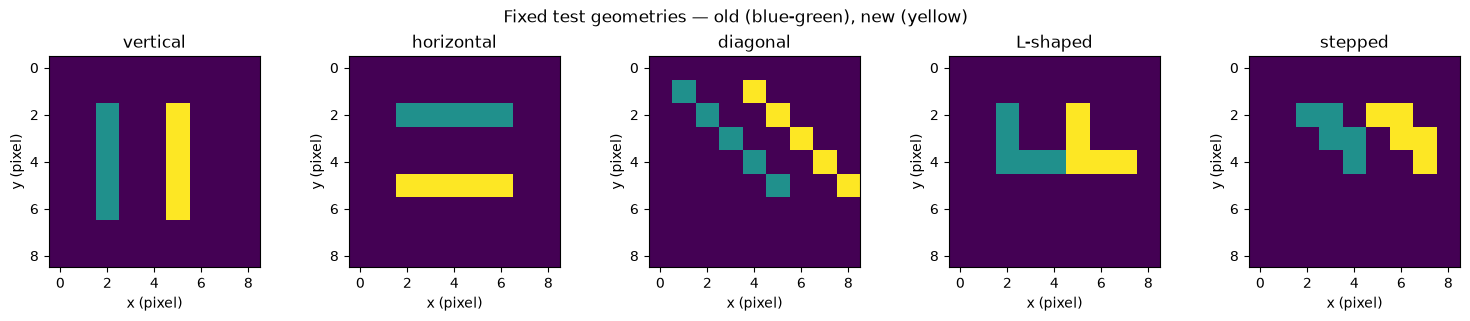

81 LIF neurons; 3620 directed inhibitory connections


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"  # Many short simulations: avoid repeated C++ compilation.


width = height = 9
n = width * height
xy = np.column_stack((np.arange(n) % width, np.arange(n) // width))
dt_ms = 0.05

def pixels(coords):
    return np.array([y * width + x for x, y in coords], dtype=int)

# Exact geometry definitions from Notebook 19 / 20.
shapes = {
    "vertical": (pixels([(2, y) for y in range(2, 7)]),
                 pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (pixels([(x, 2) for x in range(2, 7)]),
                   pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (pixels([(x, x) for x in range(1, 6)]),
                 pixels([(x + 3, x) for x in range(1, 6)])),
    "L-shaped": (pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
                 pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
                pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
}

# Reused, homogeneous surround graph (same for both models and all input shapes).
distance = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
post, pre = np.where((distance > 1.5) & (distance <= 5.5))
base_inhibition = 0.1 * np.exp(-distance[post, pre]**2 / (2 * 2.5**2))
assert all(len(a) == len(b) == 5 and len(set(a) | set(b)) == 10
           for a, b in shapes.values())

fig, axes = plt.subplots(1, 5, figsize=(15, 3.1), constrained_layout=True)
for ax, (name, (old, new)) in zip(axes, shapes.items()):
    image = np.zeros(n, dtype=int)
    image[old], image[new] = 1, 2
    ax.imshow(image.reshape(height, width), cmap="viridis", vmin=0, vmax=2,
              interpolation="nearest")
    ax.set(title=name, xlabel="x (pixel)", ylabel="y (pixel)",
           xticks=range(0, 9, 2), yticks=range(0, 9, 2))
fig.suptitle("Fixed test geometries — old (blue-green), new (yellow)")
plt.show()
print(f"{n} LIF neurons; {len(pre)} directed inhibitory connections")

## 2. Implement reference, additive control, and depressing autapses

The **STD synapse** uses a Tsodyks-type available-resource variable $x\in[0,1]$:

$$
\frac{dx}{dt}=\frac{1-x}{\tau_{\rm rec}},\qquad
\begin{cases}
I_{\rm exc,post}\leftarrow I_{\rm exc,post}+J_0x,\\
x\leftarrow (1-U)x
\end{cases}
\quad\text{at each presynaptic recurrent spike.}
$$

$J_0$ is the **initial current increment** when $x=1$; $U$ is the depleted fraction per spike; $\tau_{\rm rec}$ is the resource recovery time. Equivalently, $J_0=WU$ in a synaptic model using a maximum scale $W$. The synapse recovers in silence—it does **not** decay like sensory support. Therefore **fading is a hypothesis to test**, not a consequence guaranteed by STD.

The updates use Brian2's ordinary spike-triggered synapses. Recurrent currents are **additive**. The STD state belongs to the **synapse**, not to the neuron. Brian2's exact state updater is used for the linear neuronal dynamics, and its event-driven update for $x$.

In [2]:
def simulate(schedule, *, mode, weight, refractory_ms, U=0.1, tau_rec_ms=120.,
             duration_ms=260., n_neurons=n, trace_ids=None):
    b2.start_scope()
    b2.defaultclock.dt = dt_ms * b2.ms

    event_ids, event_times = [], []
    for ids, pulses, stagger_ms in schedule:
        for pulse in pulses:
            for j, pixel in enumerate(ids):
                event_ids.append(int(pixel))
                event_times.append(float(pulse) + j * stagger_ms)
    order = np.argsort(event_times, kind="stable")
    camera = b2.SpikeGeneratorGroup(
        n_neurons, np.asarray(event_ids, dtype=int)[order],
        np.asarray(event_times, dtype=float)[order] * b2.ms)

    parameters = dict(tau_m=10*b2.ms, tau_ext=3*b2.ms,
                      tau_exc=5*b2.ms, tau_inh=12*b2.ms,
                      tau_support=120*b2.ms, v_threshold=1., camera_gain=22.)
    equations = """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """
    if mode != "std":
        equations += "dsupport/dt = -support/tau_support : 1\n"
    neurons = b2.NeuronGroup(
        n_neurons, equations, threshold="v > v_threshold", reset="v = 0",
        refractory=refractory_ms*b2.ms if refractory_ms else False,
        method="exact", namespace=parameters)

    camera_update = "Iext_post += camera_gain"
    if mode != "std":
        camera_update += "; support_post = 1"
    feed = b2.Synapses(camera, neurons, on_pre=camera_update, namespace=parameters)
    feed.connect(j="i")

    if mode == "std":
        recurrence = b2.Synapses(
            neurons, neurons,
            "dx/dt = (1-x)/tau_rec : 1 (event-driven)",
            on_pre="Iexc_post += J0*x; x = x*(1-U)",
            namespace={"J0": float(weight), "U": float(U),
                       "tau_rec": float(tau_rec_ms)*b2.ms})
    elif mode == "refresh":
        recurrence = b2.Synapses(
            neurons, neurons, on_pre="Iexc_post = recurrence_gain*support_post",
            namespace={"recurrence_gain": float(weight)})
    elif mode == "additive":
        recurrence = b2.Synapses(
            neurons, neurons, on_pre="Iexc_post += recurrence_gain*support_post",
            namespace={"recurrence_gain": float(weight)})
    else:
        raise ValueError(mode)
    recurrence.connect(i=np.arange(n_neurons), j=np.arange(n_neurons))
    if mode == "std":
        recurrence.x = 1.

    spikes = b2.SpikeMonitor(neurons)
    objects = [camera, neurons, feed, recurrence, spikes]
    if n_neurons == n:
        inhibition = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
        inhibition.connect(i=pre, j=post)
        inhibition.w = base_inhibition
        objects.append(inhibition)
    if trace_ids is not None:
        variables = ["v", "Iext", "Iexc", "Iinh"]
        if mode != "std":
            variables.append("support")
        state = b2.StateMonitor(neurons, variables, record=trace_ids)
        objects.append(state)
        if mode == "std":
            resource = b2.StateMonitor(recurrence, "x", record=trace_ids)
            objects.append(resource)

    b2.Network(*objects).run(duration_ms*b2.ms)
    result = {"t": np.asarray(spikes.t/b2.ms),
              "i": np.asarray(spikes.i, dtype=int)}
    if trace_ids is not None:
        result["time"] = np.asarray(state.t/b2.ms)
        for var in variables:
            result[var] = np.asarray(getattr(state, var))
        if mode == "std":
            result["x"] = np.asarray(resource.x)
    return result

reference = dict(mode="refresh", weight=8., refractory_ms=0.)
additive = dict(mode="additive", weight=3., refractory_ms=1.)
old_pulses = (2., 4., 6.)
windows = ((32., 42.), (42., 52.))

def pulse_schedule(old, new, second_start=20., row_delay=0.):
    return ((old, old_pulses, row_delay),
            (new, (second_start, second_start+2., second_start+4.), row_delay))

print("Approved reference:", reference)
print("Additive + support control:", additive)
print("STD mode contains no support state or camera-to-support update.")

Approved reference: {'mode': 'refresh', 'weight': 8.0, 'refractory_ms': 0.0}
Additive + support control: {'mode': 'additive', 'weight': 3.0, 'refractory_ms': 1.0}
STD mode contains no support state or camera-to-support update.


## 3. Isolated-neuron calibration: persistence, fading and firing rate

First stimulate one neuron at 2, 4 and 6 ms. It is equivalent to stimulating a single pixel of the full network because every other neuron remains silent; the isolated neuron has no lateral input.

Select a **small diagnostic grid** in terms of the actual initial current increment $J_0$ rather than a poorly interpretable product $WU$:

$$J_0\in\{1,2,3,4,6,8\},\quad U\in\{0.05,0.10,0.20\},\quad
\tau_{\rm rec}\in\{60,120\}\ \mathrm{ms}.$$

For each run, compare: last recurrent spike (target close to reference), number of spikes after the last camera event, minimum interspike interval, and whether the circuit remains active during the **late silent-input tail**. We do not infer successful fading merely from a simulation stopping; a candidate whose last spikes occur near 260 ms is flagged as potentially persistent indefinitely.

This is *calibration on the isolated neuron only*. The five geometry tests below are held out from parameter selection.

In [3]:
solo_schedule = [(np.array([0], dtype=int), old_pulses, 0.)]

def spike_metrics(run, end_ms=260.):
    t = run["t"]
    after_input = t[t >= 10.]
    intervals = np.diff(t)
    return dict(spikes_after_input=len(after_input),
                last_spike_ms=float(t[-1]) if len(t) else np.nan,
                minimum_isi_ms=float(intervals.min()) if len(intervals) else np.nan,
                spikes_200_260=int(np.sum((t >= 200.) & (t < end_ms))))

solo_reference = simulate(solo_schedule, **reference, n_neurons=1)
solo_additive = simulate(solo_schedule, **additive, n_neurons=1)
reference_metrics = spike_metrics(solo_reference)
print("Reference isolated neuron:", reference_metrics)
print("Additive + support control:", spike_metrics(solo_additive))

initial_increments = (1., 2., 3., 4., 6., 8.)
utilizations = (0.05, 0.10, 0.20)
recovery_times = (60., 120.)

rows = []
for J0 in tqdm(initial_increments, desc="Initial synaptic increment"):
    for U in utilizations:
        for tau_rec in recovery_times:
            setting = dict(mode="std", weight=J0, refractory_ms=1.,
                           U=U, tau_rec_ms=tau_rec)
            result = simulate(solo_schedule, **setting, n_neurons=1)
            rows.append(dict(J0=J0, U=U, tau_rec_ms=tau_rec,
                             **spike_metrics(result)))
calibration = pd.DataFrame(rows)

# The target is matched post-input persistence, not merely a high spike count.
calibration["duration_error_ms"] = abs(calibration.last_spike_ms - reference_metrics["last_spike_ms"])
calibration["spike_count_error"] = abs(calibration.spikes_after_input - reference_metrics["spikes_after_input"])
calibration["still_active_at_end"] = calibration.spikes_200_260 > 0
calibration["score"] = (calibration.duration_error_ms
                        + 0.1*calibration.spike_count_error
                        + 300*calibration.still_active_at_end.astype(int))
calibration = calibration.sort_values("score").reset_index(drop=True)
display(calibration)

# Select a few configurations *without* looking at their spatial replacement scores.
selected = calibration.head(4).copy()
print("STD configurations selected for spatial evaluation:")
display(selected[["J0", "U", "tau_rec_ms", "last_spike_ms", "spikes_after_input"]])

Reference isolated neuron: {'spikes_after_input': 34, 'last_spike_ms': 89.2, 'minimum_isi_ms': 0.2499999999999991, 'spikes_200_260': 0}
Additive + support control: {'spikes_after_input': 64, 'last_spike_ms': 85.7, 'minimum_isi_ms': 0.9999999999999929, 'spikes_200_260': 0}


Initial synaptic increment:   0%|          | 0/6 [00:00<?, ?it/s]WARNING    The name "tau_rec" refers to different objects in different namespaces used for resolving names in the context of group "synapses_1". Will use the object from the group-specific namespace with the value 60. * msecond, but the name also refers to a variable in the run namespace with value '60.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "tau_rec" refers to different objects in different namespaces used for resolving names in the context of group "synapses_1". Will use the object from the group-specific namespace with the value 120. * msecond, but the name also refers to a variable in the run namespace with value '120.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
Initial synaptic increment: 100%|██████████| 6/6 [00:09<00:00,  1.63s/it]


,J0,U,tau_rec_ms,spikes_after_input,last_spike_ms,minimum_isi_ms,spikes_200_260,duration_error_ms,spike_count_error,still_active_at_end,score
0,8.0,0.05,120.0,47,70.00,1.0,0,19.20,13,False,20.50
1,6.0,0.05,120.0,34,53.30,1.0,0,35.90,0,False,35.90
2,4.0,0.05,60.0,25,43.70,1.0,0,45.50,9,False,46.40
3,4.0,0.05,120.0,22,41.50,1.0,0,47.70,12,False,48.90
4,8.0,0.10,120.0,21,40.85,1.0,0,48.35,13,False,49.65
5,6.0,0.10,60.0,19,36.40,1.0,0,52.80,15,False,54.30
6,3.0,0.05,120.0,15,34.70,1.0,0,54.50,19,False,56.40
7,3.0,0.05,60.0,16,33.45,1.0,0,55.75,18,False,57.55
8,6.0,0.10,120.0,16,31.40,1.0,0,57.80,18,False,59.60
9,4.0,0.10,60.0,12,27.35,1.0,0,61.85,22,False,64.05


STD configurations selected for spatial evaluation:


,J0,U,tau_rec_ms,last_spike_ms,spikes_after_input
0,8.0,0.05,120.0,70.0,47
1,6.0,0.05,120.0,53.3,34
2,4.0,0.05,60.0,43.7,25
3,4.0,0.05,120.0,41.5,22


## 4. Inspect the isolated-neuron trajectories

A model can match the reference's last spike while using a very different mechanism. Plot spike times, the excitatory current and (for STD) available resources $x(t)$. Specifically, **decreasing $x$ is depression; recovering $x$ after silence is not sensory fading**. A candidate that maintains self-sustained firing despite depression is not a valid replacement for the transient support mechanism.

Isolated traces:  67%|██████▋   | 4/6 [00:01<00:00,  2.78it/s]WARNING    The name "J0" refers to different objects in different namespaces used for resolving names in the context of group "synapses_1". Will use the object from the group-specific namespace with the value 4.0, but the name also refers to a variable in the run namespace with value '8.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "tau_rec" refers to different objects in different namespaces used for resolving names in the context of group "synapses_1". Will use the object from the group-specific namespace with the value 60. * msecond, but the name also refers to a variable in the run namespace with value '120.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
Isolated traces: 100%|██████████| 6/6 [00:02<00:00,  2.80it/s]


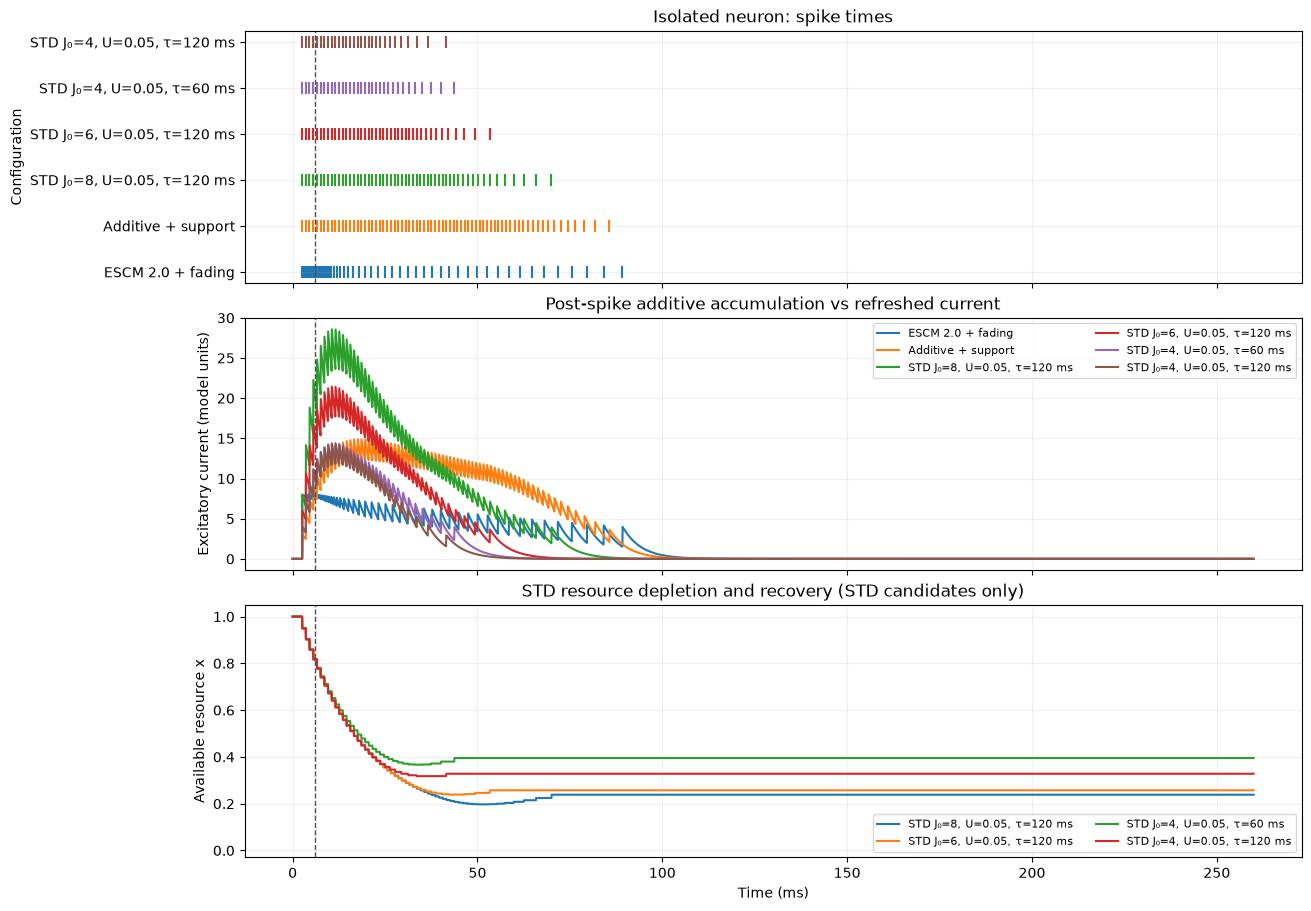

In [4]:
trace_settings = [("ESCM 2.0 + fading", reference),
                  ("Additive + support", additive)]
for row in selected.itertuples(index=False):
    trace_settings.append((f"STD J₀={row.J0:g}, U={row.U:g}, τ={row.tau_rec_ms:g} ms",
                           dict(mode="std", weight=float(row.J0), refractory_ms=1.,
                                U=float(row.U), tau_rec_ms=float(row.tau_rec_ms))))

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True, constrained_layout=True)
for label, setting in tqdm(trace_settings, desc="Isolated traces"):
    run = simulate(solo_schedule, **setting, n_neurons=1, trace_ids=[0])
    axes[0].scatter(run["t"], np.full(len(run["t"]), label), marker="|", s=70)
    axes[1].plot(run["time"], run["Iexc"][0], label=label)
    if "x" in run:
        axes[2].plot(run["time"], run["x"][0], label=label)
axes[0].set(ylabel="Configuration", title="Isolated neuron: spike times")
axes[1].set(ylabel="Excitatory current (model units)", title="Post-spike additive accumulation vs refreshed current")
axes[2].set(xlabel="Time (ms)", ylabel="Available resource x", ylim=(-0.03, 1.05),
            title="STD resource depletion and recovery (STD candidates only)")
for ax in axes:
    ax.axvline(6., color="0.3", ls="--", lw=1, label="Last camera event" if ax is axes[0] else None)
    ax.grid(alpha=0.2)
axes[1].legend(loc="upper right", fontsize=8, ncol=2)
axes[2].legend(loc="lower right", fontsize=8, ncol=2)
plt.show()

## 5. Reproduce the exact five-geometry benchmark

On each geometry, run three independent scenarios: **old alone**, **new alone**, and **competition**. Each neuron is assessed separately in both $[32,42)$ and $[42,52)$ ms:

- A representation is *eligible* only when **all five** pixels spike at least twice per window in the isolated controls.
- Replacement is successful only when **all old pixels have zero spikes**, **all new pixels have at least two**, and **no outside pixel fires** in either window.
- We additionally report *late-only suppression* (old edge silent in the second window), which helps distinguish delayed competition from a complete failure.

The reference must reproduce its previously reported **3/5** strict successes under the exact fading benchmark. If this fails, investigate the reproduction before interpreting STD.

In [5]:
def pixel_counts(run, ids, start, stop):
    mask = (run["t"] >= start) & (run["t"] < stop)
    return np.bincount(run["i"][mask], minlength=n)[ids]

def evaluate_one(geometry, setting, *, second_start=20., row_delay=0.):
    old, new = shapes[geometry]
    old_input, new_input = pulse_schedule(old, new, second_start, row_delay)
    old_only = simulate([old_input], **setting, duration_ms=75.)
    new_only = simulate([new_input], **setting, duration_ms=75.)
    both = simulate([old_input, new_input], **setting, duration_ms=75.)
    outside = np.setdiff1d(np.arange(n), np.r_[old, new])
    def window_counts(run, ids):
        return np.array([pixel_counts(run, ids, a, b) for a, b in windows])

    old_control = (window_counts(old_only, old) >= 2).all(axis=0)
    new_control = (window_counts(new_only, new) >= 2).all(axis=0)
    old_silent_by_window = (window_counts(both, old) == 0).all(axis=1)
    old_silent = (window_counts(both, old) == 0).all(axis=0)
    new_persistent = (window_counts(both, new) >= 2).all(axis=0)
    off_target = (window_counts(both, outside) > 0).any(axis=0)
    eligible = bool(old_control.all() and new_control.all())
    success = bool(eligible and old_silent.all() and new_persistent.all()
                   and not off_target.any())
    return dict(geometry=geometry, eligible=eligible,
                old_control=int(old_control.sum()), new_control=int(new_control.sum()),
                old_silent=int(old_silent.sum()), new_persistent=int(new_persistent.sum()),
                off_target=int(off_target.sum()),
                old_silent_first=bool(old_silent_by_window[0]),
                old_silent_second=bool(old_silent_by_window[1]), success=success)

def evaluate_geometries(setting, names=tuple(shapes)):
    return pd.DataFrame([evaluate_one(name, setting) for name in names])

model_settings = {"ESCM 2.0 + fading": reference,
                  "Additive + support": additive}
for k, row in enumerate(selected.itertuples(index=False), 1):
    model_settings[f"STD {k}: J₀={row.J0:g}, U={row.U:g}, τ={row.tau_rec_ms:g}"] = dict(
        mode="std", weight=float(row.J0), refractory_ms=1.,
        U=float(row.U), tau_rec_ms=float(row.tau_rec_ms))

all_rows = []
for model, setting in tqdm(model_settings.items(), desc="Five-geometry comparison"):
    table = evaluate_geometries(setting)
    table.insert(0, "model", model)
    all_rows.append(table)
all_results = pd.concat(all_rows, ignore_index=True)
display(all_results)

reference_table = all_results.loc[all_results.model == "ESCM 2.0 + fading"]
assert int(reference_table.success.sum()) == 3, (
    "Approved fading reference no longer reproduces its 3/5 result; stop and inspect.")

summary = all_results.groupby("model", sort=False).agg(
    eligible=("eligible", "sum"), strict_replacements=("success", "sum"),
    old_silent_mean=("old_silent", "mean"),
    new_persistent_mean=("new_persistent", "mean"),
    late_old_silent=("old_silent_second", "sum"),
    off_target_total=("off_target", "sum"))
print("Five-geometry summary (strict 3/5 reference target):")
display(summary)

Five-geometry comparison: 100%|██████████| 6/6 [00:18<00:00,  3.05s/it]


,model,geometry,eligible,old_control,new_control,old_silent,new_persistent,off_target,old_silent_first,old_silent_second,success
0,ESCM 2.0 + fading,vertical,True,5,5,5,5,0,True,True,True
1,ESCM 2.0 + fading,horizontal,True,5,5,5,5,0,True,True,True
2,ESCM 2.0 + fading,diagonal,True,5,5,4,5,0,False,False,False
3,ESCM 2.0 + fading,L-shaped,True,5,5,5,4,0,True,True,False
4,ESCM 2.0 + fading,stepped,True,5,5,5,5,0,True,True,True
5,Additive + support,vertical,True,5,5,0,5,0,False,True,False
6,Additive + support,horizontal,True,5,5,0,5,0,False,True,False
7,Additive + support,diagonal,True,5,5,0,5,0,False,False,False
8,Additive + support,L-shaped,True,5,5,0,5,0,False,False,False
9,Additive + support,stepped,True,5,5,0,5,0,False,False,False


Five-geometry summary (strict 3/5 reference target):


,eligible,strict_replacements,old_silent_mean,new_persistent_mean,late_old_silent,off_target_total
model,,,,,,
ESCM 2.0 + fading,5,3,4.8,4.8,4,0
Additive + support,5,0,0.0,5.0,2,0
"STD 1: J₀=8, U=0.05, τ=120",5,0,0.0,5.0,0,0
"STD 2: J₀=6, U=0.05, τ=120",1,0,0.0,5.0,5,0
"STD 3: J₀=4, U=0.05, τ=60",0,0,4.6,5.0,5,0
"STD 4: J₀=4, U=0.05, τ=120",0,0,4.6,5.0,5,0


## 6. Compare the spatial outcomes visually

Showing only an aggregate score can conceal the failure mode. The heatmaps below show **how many of the five old pixels become silent** and **how many new pixels remain active** across the same five geometries. A passing result requires both (plus eligible isolated controls and no off-target spikes).

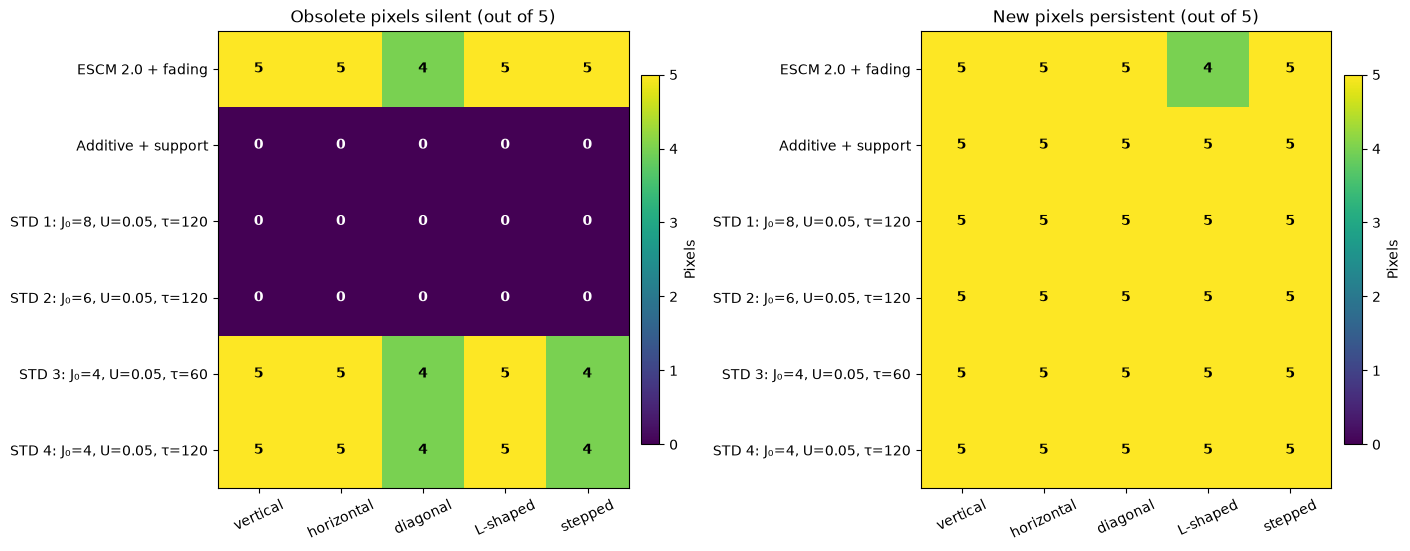

In [6]:
models = list(model_settings)
geometries = list(shapes)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), constrained_layout=True)
for ax, value, title in zip(axes,
                            ("old_silent", "new_persistent"),
                            ("Obsolete pixels silent (out of 5)", "New pixels persistent (out of 5)")):
    pivot = all_results.pivot(index="model", columns="geometry", values=value)
    pivot = pivot.loc[models, geometries]
    image = ax.imshow(pivot, cmap="viridis", vmin=0, vmax=5, aspect="auto")
    ax.set(title=title, xticks=np.arange(len(geometries)), xticklabels=geometries,
           yticks=np.arange(len(models)), yticklabels=models)
    ax.tick_params(axis="x", rotation=25)
    for r in range(len(models)):
        for c in range(len(geometries)):
            v = int(pivot.iloc[r, c])
            ax.text(c, r, str(v), ha="center", va="center",
                    color="white" if v < 3 else "black", fontweight="bold")
    fig.colorbar(image, ax=ax, fraction=0.045, pad=0.03, label="Pixels")
plt.show()

## 7. Diagnose the best STD candidate during replacement

The original current-balance experiment (Notebook 26) found **delayed suppression** in additive + support: between 32–42 ms, obsolete neurons still had a large positive mean net input; by 42–52 ms they had stopped spiking.

To test whether STD addresses that mechanism, record all ten edge neurons during the same vertical replacement. Compare the mean old-edge $I_{\rm exc}$, $I_{\rm inh}$ and net drive $I_{\rm ext}+I_{\rm exc}-I_{\rm inh}$ over time. Plot the STD resource fraction $x$ separately. An STD candidate can fail because recurrent resources deplete **too fast** (no isolated persistence), **too slowly** (old edge resists inhibition), or because the new edge cannot establish itself.

Replacement current traces: 100%|██████████| 3/3 [00:00<00:00,  4.66it/s]


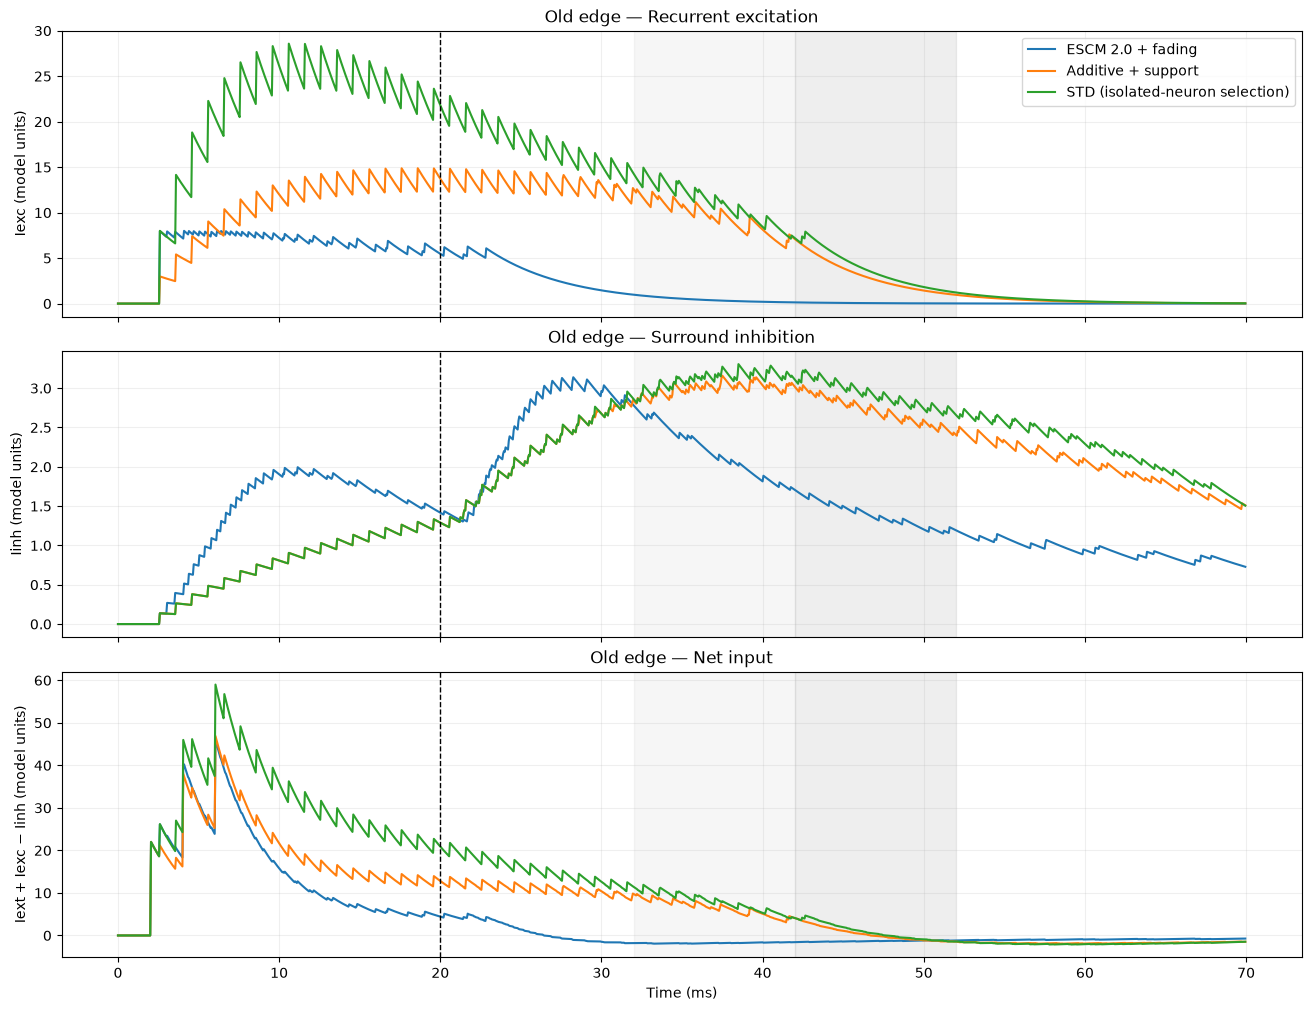

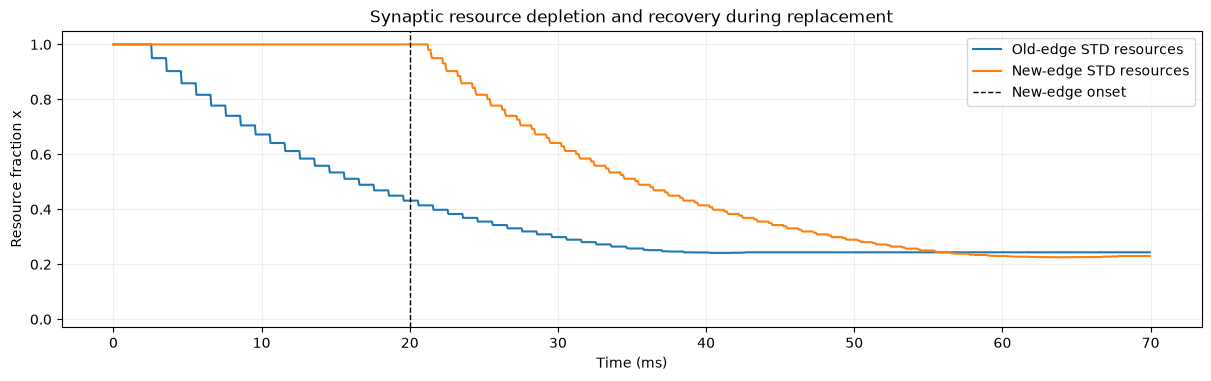

,model,window,old_spikes,new_spikes,old_mean_exc,old_mean_inh,old_mean_net
0,ESCM 2.0 + fading,32–42 ms,0,20,0.423576,2.193372,-1.767798
1,ESCM 2.0 + fading,42–52 ms,0,17,0.057325,1.388634,-1.331238
2,Additive + support,32–42 ms,29,50,9.532620,2.992732,6.541885
3,Additive + support,42–52 ms,0,44,3.081868,2.713641,0.368298
4,STD (isolated-neuron selection),32–42 ms,35,50,11.076714,3.110674,7.968037
5,STD (isolated-neuron selection),42–52 ms,4,50,3.820567,2.922118,0.898520


In [7]:
old, new = shapes["vertical"]
observed = np.r_[old, new]
old_input, new_input = pulse_schedule(old, new)

# The first STD setting is selected solely from isolated-neuron calibration.
chosen_std = next(setting for setting in model_settings.values() if setting["mode"] == "std")
trace_models = {"ESCM 2.0 + fading": reference,
                "Additive + support": additive,
                "STD (isolated-neuron selection)": chosen_std}
traces = {}
for label, setting in tqdm(trace_models.items(), desc="Replacement current traces"):
    traces[label] = simulate([old_input, new_input], **setting,
                             duration_ms=70., trace_ids=list(observed))

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, constrained_layout=True)
for name, run in traces.items():
    t = run["time"]
    old_exc = run["Iexc"][:5].mean(axis=0)
    old_inh = run["Iinh"][:5].mean(axis=0)
    net = (run["Iext"] + run["Iexc"] - run["Iinh"])[:5].mean(axis=0)
    axes[0].plot(t, old_exc, label=name)
    axes[1].plot(t, old_inh, label=name)
    axes[2].plot(t, net, label=name)
for ax, title, ylabel in zip(axes,
                            ("Recurrent excitation", "Surround inhibition", "Net input"),
                            ("Iexc", "Iinh", "Iext + Iexc − Iinh")):
    ax.set(title=f"Old edge — {title}", ylabel=f"{ylabel} (model units)")
    ax.axvspan(32, 42, alpha=0.07, color="grey")
    ax.axvspan(42, 52, alpha=0.13, color="grey")
    ax.axvline(20, ls="--", color="black", lw=1)
    ax.grid(alpha=0.2)
axes[0].legend(loc="upper right")
axes[-1].set(xlabel="Time (ms)")
plt.show()

std_trace = traces["STD (isolated-neuron selection)"]
fig, ax = plt.subplots(figsize=(12, 3.7), constrained_layout=True)
ax.plot(std_trace["time"], std_trace["x"][:5].mean(axis=0), label="Old-edge STD resources")
ax.plot(std_trace["time"], std_trace["x"][5:].mean(axis=0), label="New-edge STD resources")
ax.axvline(20, ls="--", color="black", lw=1, label="New-edge onset")
ax.set(xlabel="Time (ms)", ylabel="Resource fraction x", ylim=(-0.03, 1.05),
       title="Synaptic resource depletion and recovery during replacement")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

rows = []
for name, run in traces.items():
    for a, b in windows:
        mask = (run["time"] >= a) & (run["time"] < b)
        rows.append(dict(model=name, window=f"{a:g}–{b:g} ms",
                         old_spikes=int(pixel_counts(run, old, a, b).sum()),
                         new_spikes=int(pixel_counts(run, new, a, b).sum()),
                         old_mean_exc=float(run["Iexc"][:5, mask].mean()),
                         old_mean_inh=float(run["Iinh"][:5, mask].mean()),
                         old_mean_net=float((run["Iext"] + run["Iexc"] - run["Iinh"])[:5, mask].mean())))
display(pd.DataFrame(rows))

## 8. Interpret the comparison

**Acceptance criteria.** A standard-block replacement would need to reproduce the approved network's *combination* of recruitment, temporary persistence, eventual fading, and at least 3/5 strict geometry replacements. The isolated-neuron stage is necessary but not sufficient. A model that matches fading yet retains obsolete edges is not equivalent; a model that suppresses everything because neither edge persists is not successful replacement.

The short grid above is **diagnostic, not exhaustive**. If no STD setting preserves the isolated reference, do not use a spatial failure to reject STD in general. If isolated persistence is recovered but the old edge still survives, use the current-balance plot to decide whether resource depletion genuinely reduces its recurrent drive. A particularly important possible outcome is **non-equivalence**: standard depression recovers at rest, whereas sensory support vanishes without camera input; it may be impossible for a simple STD autapse alone to reproduce all the desired sensory-dependent behavior.

We have not introduced STP on sensory synapses, extra interneurons, recurrent spatial excitation, or any new gate. The approved ESCM 2.0 model remains unchanged. All results below are conditional on the exact tested model, geometry set, input timing and integration step.